# Applied Machine Learning (CSAI2017P) — Lab Assignment 3
## Time-Series Regression: Stock Price Prediction

Experiments 4 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Vivek Kuliyal* |
| SAP ID | *590028449* |
| Batch | *B-5* |
| Due | announced in the lab |
| Lab quiz | LQ3, after submission |

**Datasets:** C1 (daily stock OHLCV)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.3.5
pandas       2.3.3
sklearn      1.7.2


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [1]:
# TODO: load the dataset for this assignment
from sklearn.datasets import fetch_california_housing



---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Load and describe the series  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1, one ticker, ≥ 3 years.*

a. Load the daily history, parse the date column and sort ascending.
b. Plot the closing price and state the date range and number of trading days.
c. State in two lines why the row order matters here but did not in LA02.


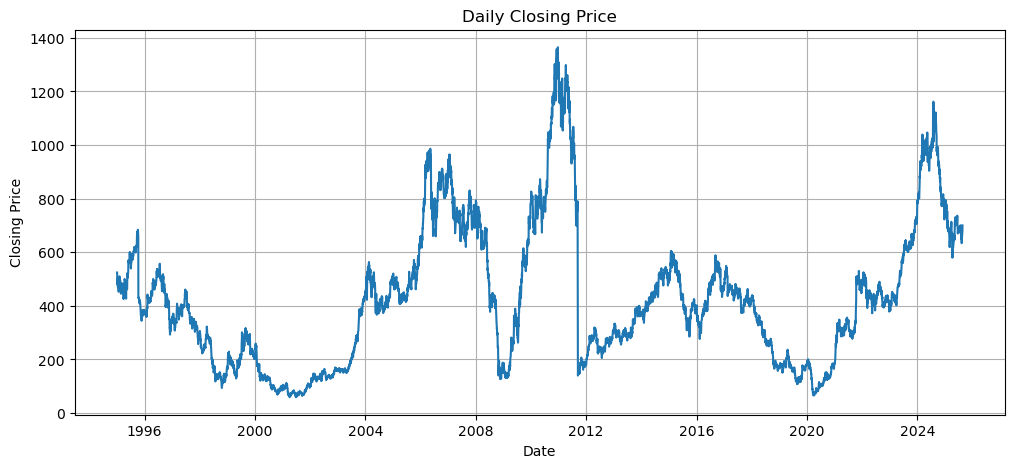

Date range: 1995-01-02 to 2025-08-19
Number of trading days: 7804

Observation:
Row order matters because stock prices are time-series data and must remain in chronological order.
In LA02, the housing observations were not time-dependent, so row order did not carry temporal information.


In [7]:
# A1 — code
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(R"C:\Users\vivek\OneDrive\Desktop\AML_Lab\EXP3\TATAMOTORS_NSE_1995-2025.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Daily Closing Price")
plt.grid(True)
plt.show()
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Number of trading days:", len(df))

**Observation (A1):**

> *Row order matters because this is time-series data, where earlier observations must come before later observations to preserve the temporal relationship.
In LA02, the California Housing observations were not time-dependent, so their row order did not carry temporal information.*

## A2. Lag features  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Create features `Close_lag1`, `Close_lag2`, `Close_lag3` and a 5-day rolling mean.
b. Set the target to the next day's close. Show the first five rows of the resulting frame.
c. Explain in two lines why the first few rows must be dropped.


In [8]:
# A2 — code
# A2 — Lag Features

# Create lag features
df["Close_lag1"] = df["Close"].shift(1)
df["Close_lag2"] = df["Close"].shift(2)
df["Close_lag3"] = df["Close"].shift(3)

# Create 5-day rolling mean
df["Close_rolling5"] = df["Close"].rolling(window=5).mean()

# Target = next day's closing price
df["Target"] = df["Close"].shift(-1)

# Drop rows containing NaN values
df_lag = df.dropna().reset_index(drop=True)

# Show first five rows
df_lag[["Date", "Close", "Close_lag1", "Close_lag2",
        "Close_lag3", "Close_rolling5", "Target"]].head()

,Date,Close,Close_lag1,Close_lag2,Close_lag3,Close_rolling5,Target
0,2011-06-01,1079.9,1095.3,1077.35,1088.85,1100.76,1048.20
1,2011-06-02,1048.2,1079.9,1095.30,1077.35,1077.92,1023.80
2,2011-06-03,1023.8,1048.2,1079.90,1095.30,1064.91,1023.70
3,2011-06-06,1023.7,1023.8,1048.20,1079.90,1054.18,1027.20
4,2011-06-07,1027.2,1023.7,1023.80,1048.20,1040.56,1028.55


**Observation (A2):**

> *The first few rows must be dropped because lag features need previous days' closing prices, which are unavailable at the beginning of the series.
The rolling mean also produces missing values initially, while the last row has no next-day close to use as the target.*

## A3. The naive baseline  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Build the baseline that predicts tomorrow's close equals today's close.
b. Report its MAE and RMSE on your test period.
c. State in two lines why any model must beat this number to be interesting.


In [ ]:
# A3 — code


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Random split versus chronological split  &nbsp;&nbsp;`[4 marks]`

*Dataset: C1.*

a. Train a `RandomForestRegressor` twice: once with `train_test_split(shuffle=True)`, once with the last 20% of dates held out.
b. Report test MAE for both and put them side by side.
c. Explain in 6–8 lines why the shuffled number is meaningless, naming the mechanism.


In [9]:
# B1 — code
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
features = ["Close_lag1", "Close_lag2", "Close_lag3", "Close_rolling5"]
X = df_lag[features]
y = df_lag["Target"]
# -------------------------------
# 1. Random split (shuffle=True)
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, shuffle=True, random_state=0
)
rf_random = RandomForestRegressor(
    n_estimators=100, random_state=0
)
rf_random.fit(X_train, y_train)
pred_random = rf_random.predict(X_test)
mae_random = mean_absolute_error(y_test, pred_random)
# ---------------------------------
# 2. Chronological split (last 20%)
# ---------------------------------
split = int(len(df_lag) * 0.80)
X_train_time = X.iloc[:split]
X_test_time = X.iloc[split:]
y_train_time = y.iloc[:split]
y_test_time = y.iloc[split:]
rf_time = RandomForestRegressor(
    n_estimators=100, random_state=0
)
rf_time.fit(X_train_time, y_train_time)
pred_time = rf_time.predict(X_test_time)
mae_time = mean_absolute_error(y_test_time, pred_time)
# -------------------------------
# Results side by side
# -------------------------------
results = pd.DataFrame({
    "Split Method": ["Random Shuffle", "Chronological (Last 20%)"],
    "Test MAE": [mae_random, mae_time]
})

print(results.to_string(index=False))

            Split Method  Test MAE
          Random Shuffle 10.780196
Chronological (Last 20%) 41.066355


**Observation (B1):**

> *The shuffled split is meaningless for time-series prediction because it mixes past and future observations.
This allows the model to train on data from periods that occur after the test observations.
The mechanism is future-data leakage (data leakage) caused by random shuffling.
Lag features are based on temporal order, so breaking that order makes the evaluation unrealistic.
A chronological split better represents the real forecasting situation.
In practice, the model is trained only on the past and tested on unseen future dates.
Therefore, the chronological MAE is the more meaningful estimate of future performance.*

## B2. Horizon and difficulty  &nbsp;&nbsp;`[4 marks]`

*Dataset: C1, chronological split throughout.*

a. Retrain your model to predict the close 1, 5 and 10 trading days ahead.
b. Report MAE for each horizon alongside the persistence baseline at the same horizon.
c. Plot MAE against horizon and explain the trend in 4–6 lines.


In [ ]:
# B2 — code


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Would you trade on it?  &nbsp;&nbsp;`[2 marks]`

*Dataset: C1.*

a. Convert your best model's predictions into an up/down direction call and report directional accuracy.
b. In 4–6 lines, state whether a low MAE with near-50% directional accuracy is useful, and why.


In [11]:
# C1 — code
# C1 — Directional Accuracy
# Use predictions from your best model
# Here, pred_time = predictions from the chronological Random Forest
# Actual direction: tomorrow's close > today's close
actual_direction = (df_lag["Target"].iloc[split:].values >
                    df_lag["Close"].iloc[split:].values)
# Predicted direction: predicted tomorrow's close > today's close
predicted_direction = (pred_time >
                       df_lag["Close"].iloc[split:].values)
# Directional accuracy
directional_accuracy = (actual_direction == predicted_direction).mean()
print("Directional Accuracy:",
      round(directional_accuracy * 100, 2), "%")

Directional Accuracy: 51.8 %


**Observation (C1):**

> *A low MAE does not necessarily mean the model is useful for trading.
If directional accuracy is close to 50%, the model is barely better than random guessing about whether the price will go up or down.
Trading decisions depend strongly on predicting the correct direction, not only the numerical closeness of the predicted price.
Therefore, near-50% directional accuracy limits the practical usefulness of the model for trading.
A useful trading model should ideally achieve directional accuracy meaningfully above 50%, along with a good MAE.*

---

## Self-check before submitting

- [X] Kernel restarted and run top-to-bottom, all outputs visible
- [X] Every attempted question has a written observation
- [X] No transformer fitted outside a pipeline
- [X] Metrics reported with units where they have any
- [X] File named `AML_LA03_<SAPID>.ipynb`
